<small>Dataset: diabetes.csv</small>

# Q33. End to End ML Pipeline

Create a complete classification workflow and tune a tree using a leakage-safe pipeline.


## Question from Classroom

Develop an End-to-End Machine Learning Pipeline 
Problem statement: Develop a complete machine learning pipeline for a real-world 
classification or regression problem of the student's choice. 
Tasks to be performed: 
1. Select a suitable dataset and define the prediction objective. 
2. Perform EDA and identify the target variable, feature types and data quality issues. 
3. Preprocess the data using suitable imputation, encoding and scaling methods. 
4. Split the dataset into training and testing sets without data leakage. 
5. Train an appropriate ML algorithm and justify the choice. 
6. Tune at least one hyperparameter using cross-validation. 
7. Evaluate the final model using suitable classification or regression metrics.


## Understand before coding

Define diabetes-label prediction -> inspect data -> replace invalid zeros -> split -> pipeline imputation and tree -> train-fold CV tuning -> held-out evaluation.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl
```


**Code layout:** 7 listed tasks → 7 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Select a suitable dataset and define the prediction objective.

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.tree import DecisionTreeClassifier,plot_tree

df=pd.read_csv("data/diabetes.csv").dropna(subset=["Outcome"])
print("Objective: predict the provided Outcome label from eight patient attributes.")


Objective: predict the provided Outcome label from eight patient attributes.


## Task 2. Perform EDA and identify the target variable, feature types and data quality issues.

This block implements the task above. Variables from earlier blocks are reused.


Shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  ...  Pedigree  Age  Outcome
0            6      148             72  ...     0.627   50        1
1            1       85             66  ...     0.351   31        0
2            8      183             64  ...     0.672   32        1
3            1       89             66  ...     0.167   21        0
4            0      137             40  ...     2.288   33        1

[5 rows x 9 columns]
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        7

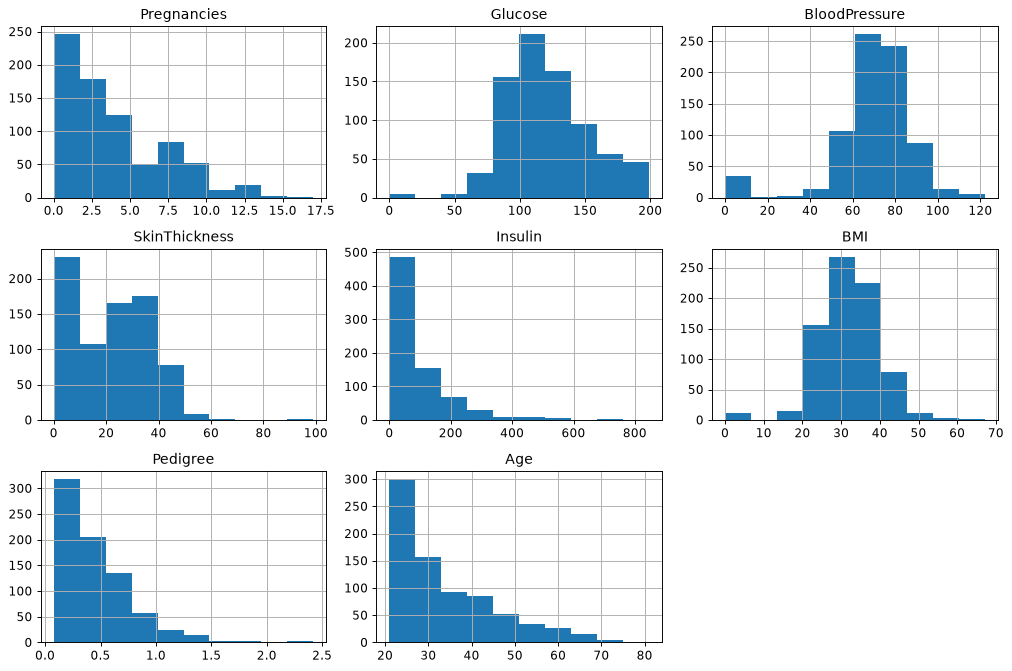

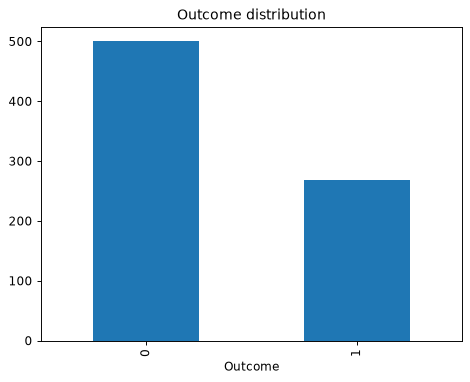

In [2]:
print("Shape:",df.shape)
print(df.head())
df.info()
print("Missing values:\n",df.isna().sum())
print("Summary:\n",df.describe(include="all").T)

X=df.drop(columns="Outcome").copy()
y=df["Outcome"]
X.hist(figsize=(12,8));plt.tight_layout();plt.show()
y.value_counts().plot(kind="bar",title="Outcome distribution");plt.show()


## Task 3. Preprocess the data using suitable imputation, encoding and scaling methods.

This block implements the task above. Variables from earlier blocks are reused.


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
zero_missing=["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
X[zero_missing]=X[zero_missing].replace(0,np.nan)
pipeline=Pipeline([("imputer",SimpleImputer(strategy="median")),
                   ("tree",DecisionTreeClassifier(random_state=42))])
print("Fixed invalid-zero rules applied. Imputation is defined, not yet fitted.")
print("Inputs are numeric; a tree needs neither categorical encoding nor feature scaling.")


Fixed invalid-zero rules applied. Imputation is defined, not yet fitted.
Inputs are numeric; a tree needs neither categorical encoding nor feature scaling.


## Task 4. Split the dataset into training and testing sets without data leakage.

This block implements the task above. Variables from earlier blocks are reused.


In [4]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


## Task 5. Train an appropriate ML algorithm and justify the choice.

This block implements the task above. Variables from earlier blocks are reused.


In [5]:
pipeline.fit(X_train,y_train)
print("A tree provides interpretable threshold rules for this binary classification task.")


A tree provides interpretable threshold rules for this binary classification task.


## Task 6. Tune at least one hyperparameter using cross-validation.

This block implements the task above. Variables from earlier blocks are reused.


In [6]:
from sklearn.model_selection import GridSearchCV
parameters={"tree__max_depth":[3,5,None],"tree__min_samples_leaf":[1,5,10]}
search=GridSearchCV(pipeline,parameters,cv=3,scoring="f1_weighted")
search.fit(X_train,y_train)
model=search.best_estimator_
print("Best settings:",search.best_params_,"Training CV F1:",search.best_score_)


Best settings: {'tree__max_depth': None, 'tree__min_samples_leaf': 10} Training CV F1: 0.7407448792791428


## Task 7. Evaluate the final model using suitable classification or regression metrics.

This block implements the task above. Variables from earlier blocks are reused.


Accuracy: 0.7468
Class order: [0 1]
Confusion matrix:
 [[86 14]
 [25 29]]
              precision    recall  f1-score   support

           0       0.77      0.86      0.82       100
           1       0.67      0.54      0.60        54

    accuracy                           0.75       154
   macro avg       0.72      0.70      0.71       154
weighted avg       0.74      0.75      0.74       154



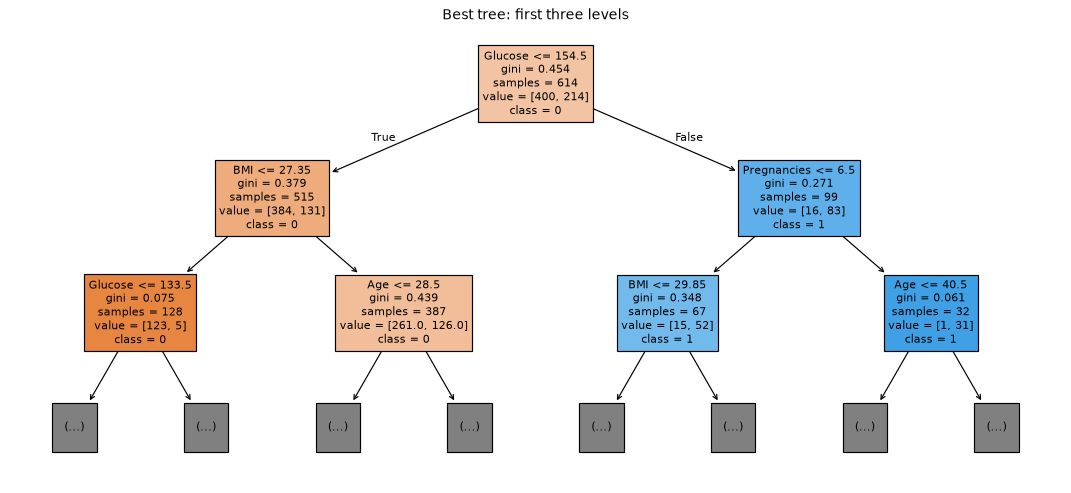

In [7]:
prediction=model.predict(X_test)

print("Accuracy:",round(accuracy_score(y_test,prediction),4))
print("Class order:",model.classes_)
print("Confusion matrix:\n",confusion_matrix(y_test,prediction,labels=model.classes_))
print(classification_report(y_test,prediction,zero_division=0))

plt.figure(figsize=(16,7))
plot_tree(model.named_steps["tree"],feature_names=X.columns.tolist(),class_names=["0","1"],max_depth=2,filled=True)
plt.title("Best tree: first three levels");plt.show()


## Viva preparation guide



**1. What are X and y?**

X contains the predictor columns; y contains the target we want to predict. X is a 2D table and y is a 1D series.

**2. Why split training and testing data?**

Fit using the training examples. Evaluate on separate examples to estimate how well the model generalizes.

**3. What do fit() and predict() mean?**

fit() learns parameters from training examples. predict() applies the learned model to new feature rows.

**4. Why random_state=42?**

It makes random splits or model choices reproducible. The number 42 has no special mathematical meaning.

**5. What is data leakage?**

Information unavailable for a real prediction accidentally influences training. Examples: including the answer in X or fitting a scaler on test data. Fit learned preprocessing only on training data.

**6. What is overfitting?**

The model learns training-specific details/noise and does worse on unseen data. Control complexity and use validation or cross-validation.

**7. What is a hyperparameter?**

A setting chosen outside model fitting, such as max_depth, K or the number of trees. Choose it using training validation, not by repeatedly optimizing the final test result.

**8. How do I fix FileNotFoundError or KeyError?**

Open Jupyter in the praceice folder, keep data/ beside this notebook, and print df.columns.tolist() to check exact column names. Do not change X and y row counts separately.

**9. What does the confusion matrix contain?**

Rows are actual classes and columns are predicted classes, in the printed label order. For binary labels [0,1], it is [[TN,FP],[FN,TP]].

**10. Define accuracy, precision, recall and F1.**

Accuracy=(TP+TN)/N. Precision=TP/(TP+FP). Recall=TP/(TP+FN). F1=2PR/(P+R). classification_report prints per-class values and macro/weighted averages. zero_division=0 handles an undefined score.

**11. Why can accuracy be misleading?**

If most examples belong to one class, always predicting that class may give high accuracy. Inspect minority-class recall, precision, F1 and the confusion matrix.

**12. Why stratify=y?**

It approximately preserves class proportions in training and test splits. Each class needs enough examples.

**13. How does a decision tree work?**

It asks feature-threshold questions, sending records down branches until a leaf predicts a class.

**14. Gini impurity?**

Gini=1-sum(p_i^2). It is zero for a pure node. A split is chosen to reduce weighted child impurity.

**15. Entropy?**

Entropy=-sum(p_i*log2(p_i)), with zero-probability terms treated as zero. Information gain is parent entropy minus weighted child entropy.

**16. Why limit max_depth?**

Very deep trees can memorize noise. Limiting depth often reduces overfitting and makes the plotted tree easier to explain.

**17. Why this objective and model?**

Outcome is an existing labeled binary target. A decision tree provides inspectable rules, handles nonlinear splits and does not require feature scaling.

**18. Why no categorical feature encoder?**

All selected diabetes features are numeric in this file. Encoding is unnecessary here; a mixed-type dataset would need an encoder such as OneHotEncoder in a ColumnTransformer.

**19. Why is zero handling outside the pipeline?**

A fixed, explicitly declared rule replaces physiologically invalid zeros with missing values. It learns no statistics. The medians learned from data are inside the pipeline.

**20. What does tree__max_depth mean?**

The double underscore addresses the max_depth setting of the pipeline step named tree. GridSearchCV can tune nested estimator parameters this way.

**21. Why put imputation inside CV?**

Imputing all training rows before cross-validation would let each validation fold influence its own medians. The pipeline refits preprocessing on each fold's fitting rows.

**22. What is the final model?**

best_estimator_ is the full pipeline refitted on all training rows using the best cross-validation settings. Call predict on raw feature rows; it imputes automatically.

**23. What should the conclusion include?**

The target and feature choices, invalid-zero and missing-value treatment, tuning method, best settings, held-out metrics and limitations such as class imbalance and limited external validation.


### Task-to-code map

- **Block 1:** Select a suitable dataset and define the prediction objective.
- **Block 2:** Perform EDA and identify the target variable, feature types and data quality issues.
- **Block 3:** Preprocess the data using suitable imputation, encoding and scaling methods.
- **Block 4:** Split the dataset into training and testing sets without data leakage.
- **Block 5:** Train an appropriate ML algorithm and justify the choice.
- **Block 6:** Tune at least one hyperparameter using cross-validation.
- **Block 7:** Evaluate the final model using suitable classification or regression metrics.
